In [2]:
# Import required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset path
file_path = r"C:\Users\Admin\Obesity-Ml-Project\data\Dhaka Obesity.csv"

# Check file and load dataset
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    raise FileNotFoundError(f"Dataset not found: {file_path}")


Dataset loaded successfully!
Dataset shape: (2182, 17)


,Gender,Age,Height (m),Weight (kg),Family history of overweight,High caloric food consumption,Vegetable consumption frequency,Daily main meals frequency,Between-meal food consumption frequency,Smoking,Alcohol intake,Daily water intake,Monitor calories,Physical exercise,Daily device usage duration,Mode of transportation,Obesity level
0,Male,29,1.65,101.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Private Car,Obesity_Type_II
1,Female,25,1.65,53.0,No,No,Always,Three,Always,No,I do not drink,Between 1 and 2 L,No,Almost Everyday,More than 5 hours,Public Transportation,Normal_Weight
2,Male,23,1.70,70.0,No,No,Always,Between 1-2,Sometimes,Yes,Sometimes,Less than a liter,No,I do not have,More than 5 hours,Public Transportation,Normal_Weight
3,Male,22,1.68,112.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Public Transportation,Obesity_Type_II
4,Male,19,1.75,67.0,No,Yes,Always,Three,Sometimes,Yes,I do not drink,Between 1 and 2 L,No,2 or 4 days,3-5 hours,Bike,Normal_Weight


In [3]:

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)


Column Names:
['Gender', 'Age', 'Height (m)', 'Weight (kg)', 'Family history of overweight', 'High caloric food consumption', 'Vegetable consumption frequency', 'Daily main meals frequency', 'Between-meal food consumption frequency', 'Smoking', 'Alcohol intake', 'Daily water intake', 'Monitor calories', 'Physical exercise', 'Daily device usage duration', 'Mode of transportation', 'Obesity level']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2182 entries, 0 to 2181
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Gender                                   2182 non-null   object 
 1   Age                                      2182 non-null   int64  
 2   Height (m)                               2182 non-null   float64
 3   Weight (kg)                              2182 non-null   float64
 4   Family history of overweight             2182 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,2182,2,Male,1265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2182.0,NaN,NaN,NaN,26.752062,8.425983,15.0,22.0,24.0,28.0,75.0
Height (m),2182.0,NaN,NaN,NaN,1.627635,0.101239,1.22,1.57,1.63,1.7,1.88
Weight (kg),2182.0,NaN,NaN,NaN,73.814207,20.83737,35.0,56.0,72.0,89.0,150.0
Family history of overweight,2182,2,No,1354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
High caloric food consumption,2182,2,Yes,1223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vegetable consumption frequency,2182,3,Sometimes,1455,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Daily main meals frequency,2182,3,Three,1294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Between-meal food consumption frequency,2182,4,Sometimes,1095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking,2182,2,No,1898,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

TARGET = "Obesity level"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove rows where the target is missing
df = df.dropna(subset=[TARGET]).copy()

# Display target class counts
print("Obesity Level Distribution:")
print(df[TARGET].value_counts())

# Display target class percentages
print("\nClass Percentages:")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))


Obesity Level Distribution:
Obesity level
Normal_Weight          530
Overweight             423
Insufficient_Weight    378
Obesity_Type_I         317
Obesity_Type_II        283
Obesity_Type_III       251
Name: count, dtype: int64

Class Percentages:
Obesity level
Normal_Weight          24.29
Overweight             19.39
Insufficient_Weight    17.32
Obesity_Type_I         14.53
Obesity_Type_II        12.97
Obesity_Type_III       11.50
Name: proportion, dtype: float64


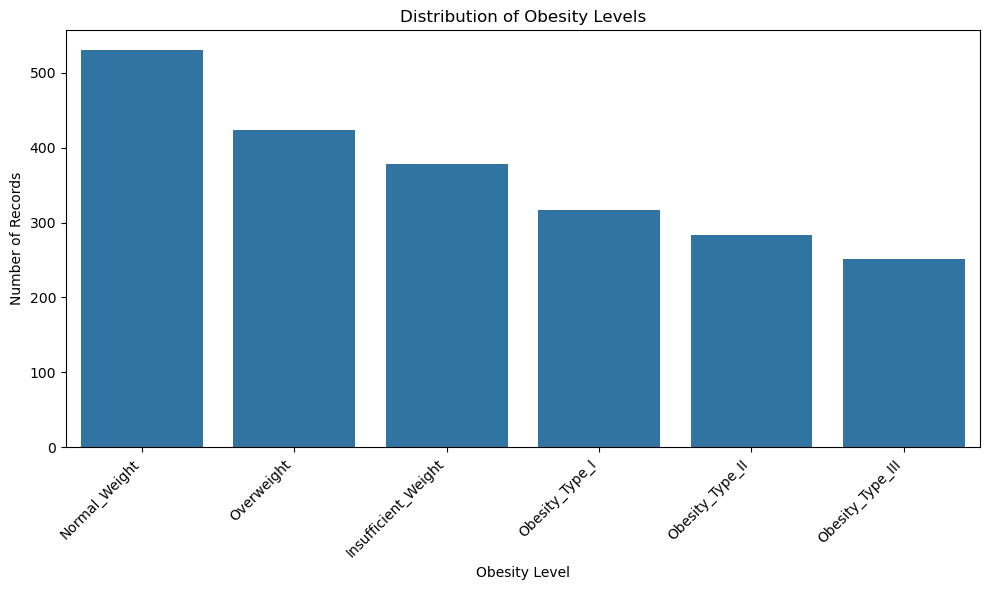

In [6]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x=TARGET,
    order=df[TARGET].value_counts().index
)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Numerical Features: ['Age', 'Height (m)', 'Weight (kg)']

Categorical Features: ['Gender', 'Family history of overweight', 'High caloric food consumption', 'Vegetable consumption frequency', 'Daily main meals frequency', 'Between-meal food consumption frequency', 'Smoking', 'Alcohol intake', 'Daily water intake', 'Monitor calories', 'Physical exercise', 'Daily device usage duration', 'Mode of transportation']


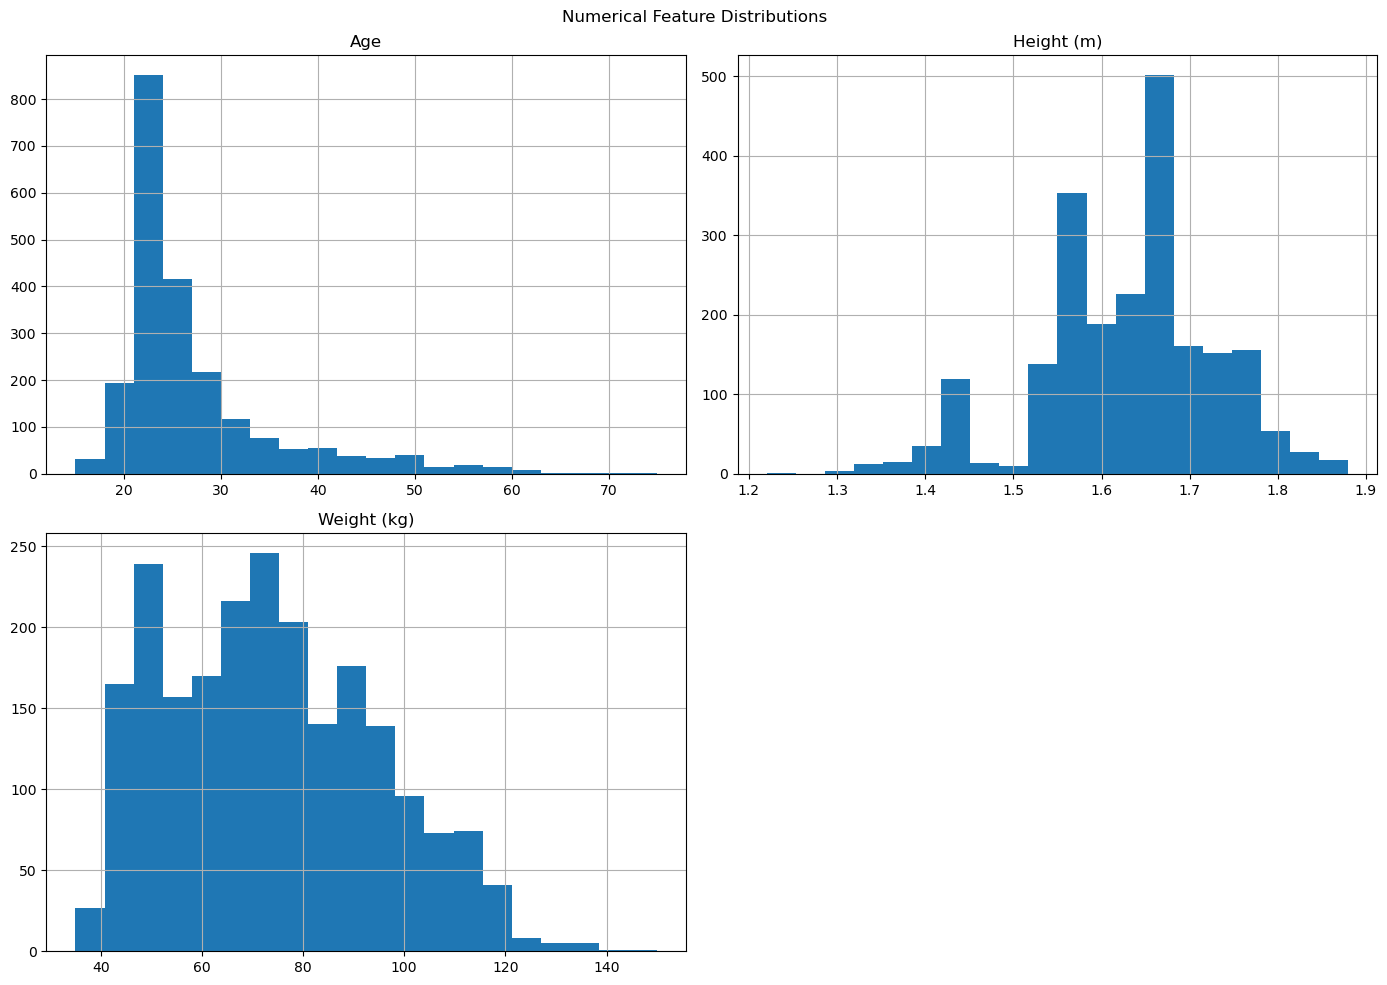

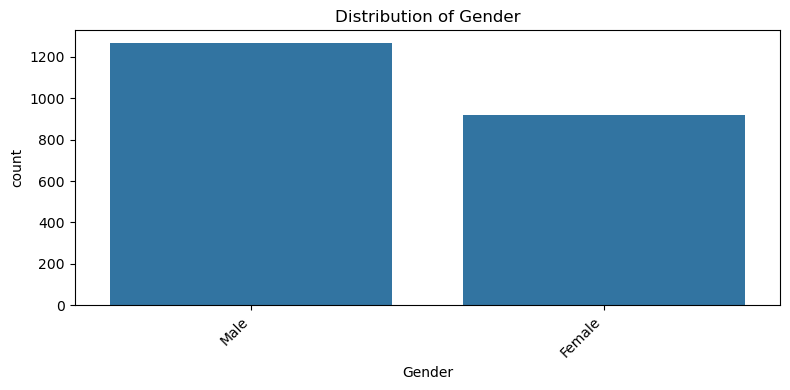

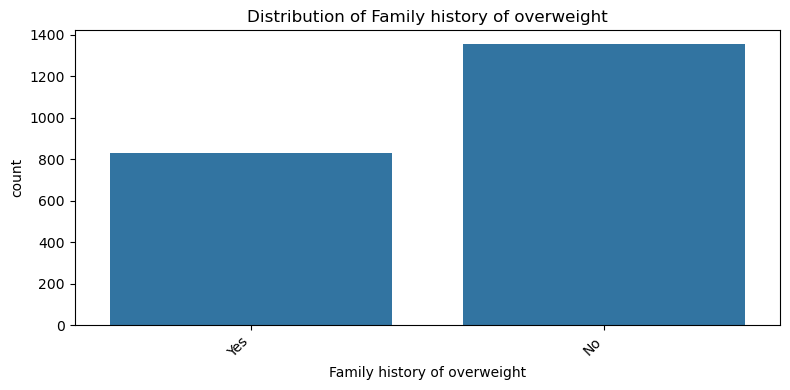

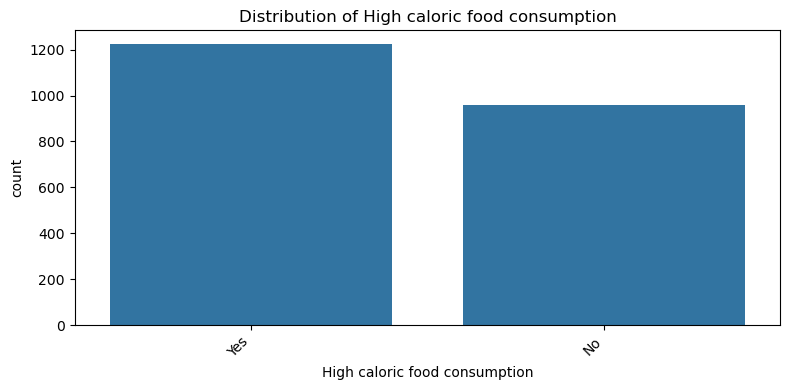

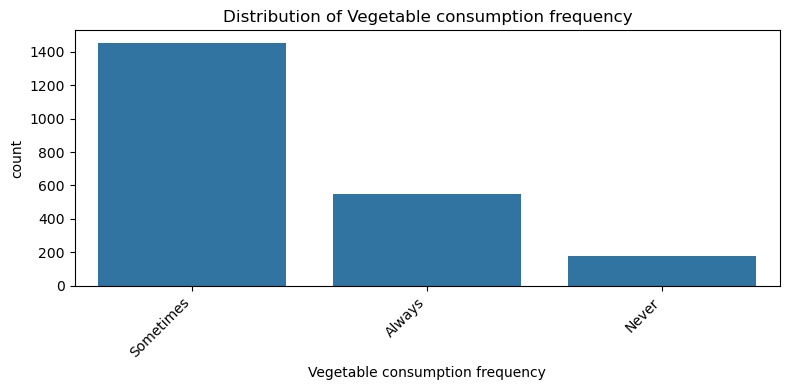

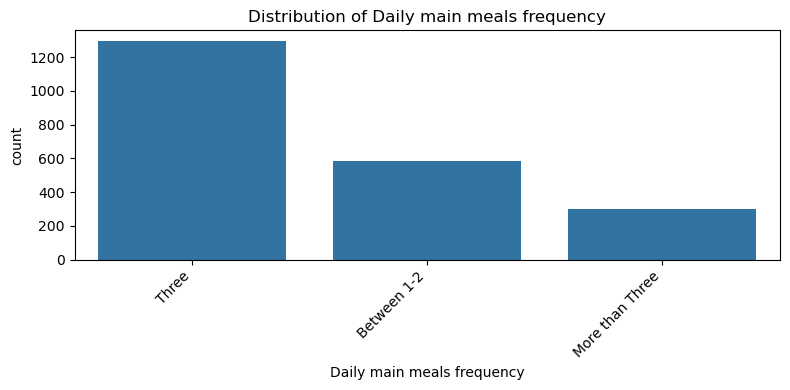

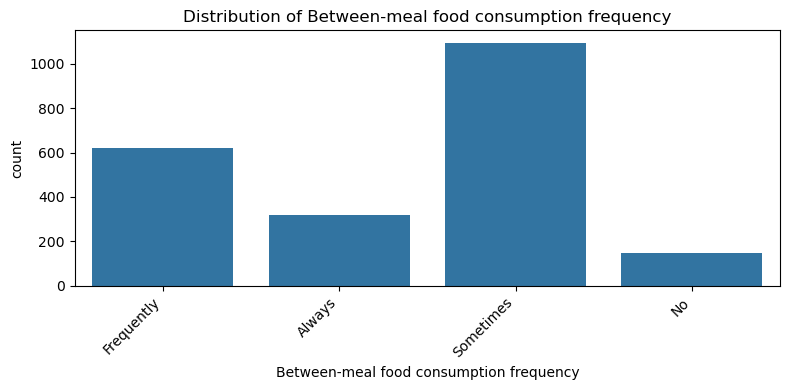

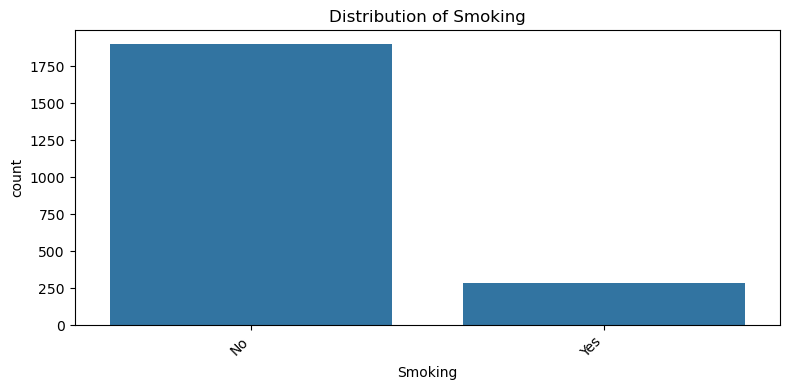

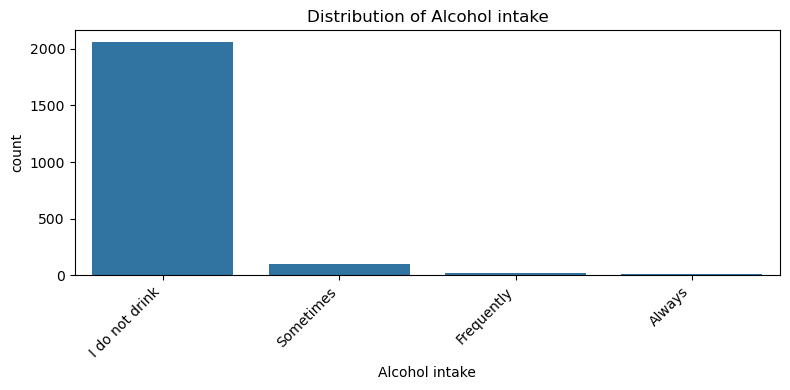

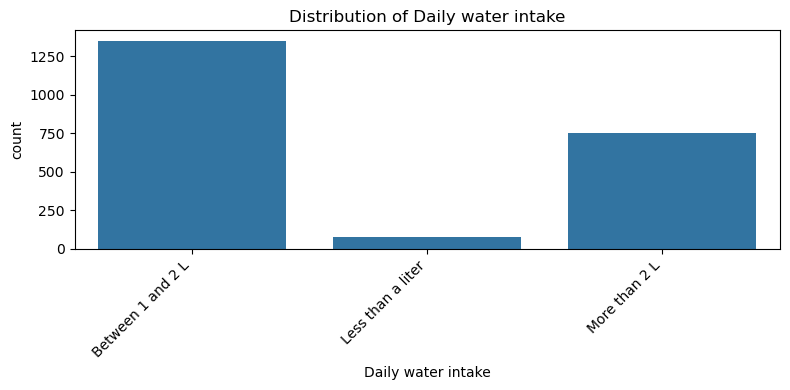

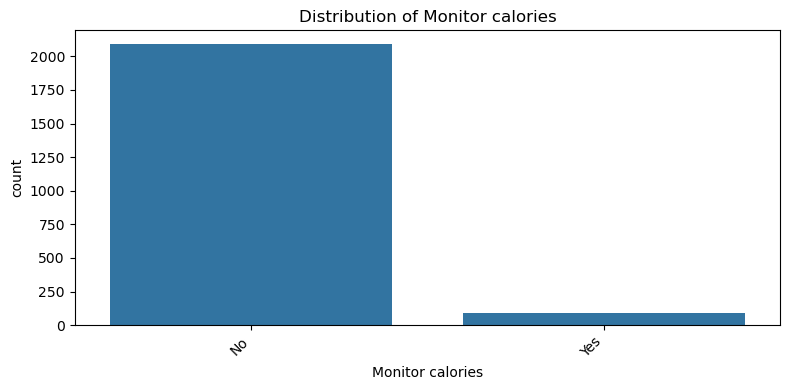

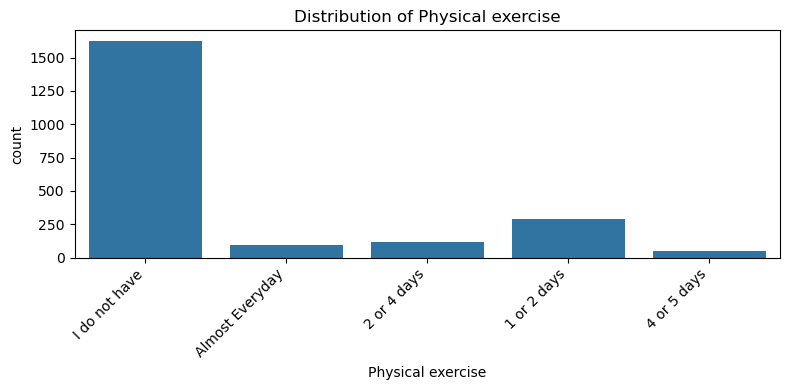

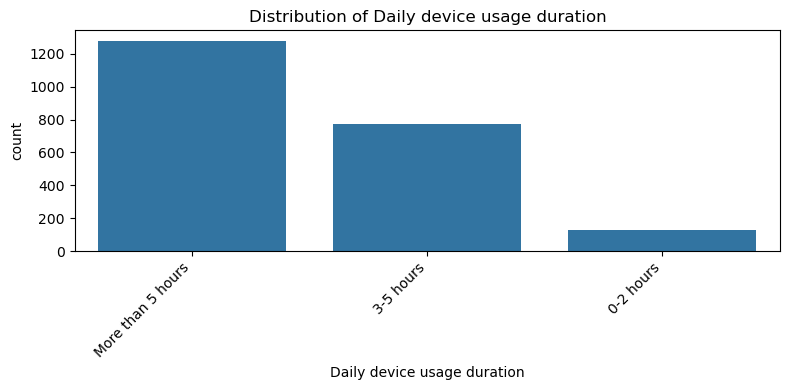

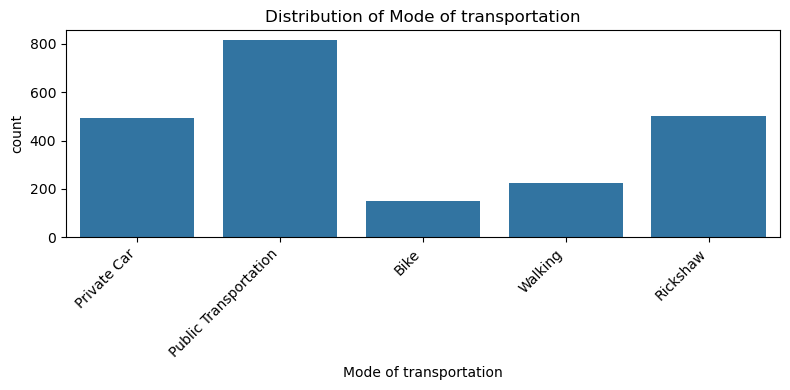

In [7]:

# Separate input features from the target
X = df.drop(columns=[TARGET])

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# Plot numerical feature distributions
if numeric_features:
    X[numeric_features].hist(figsize=(14, 10), bins=20)
    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

# Plot categorical feature distributions
for column in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=column)
    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


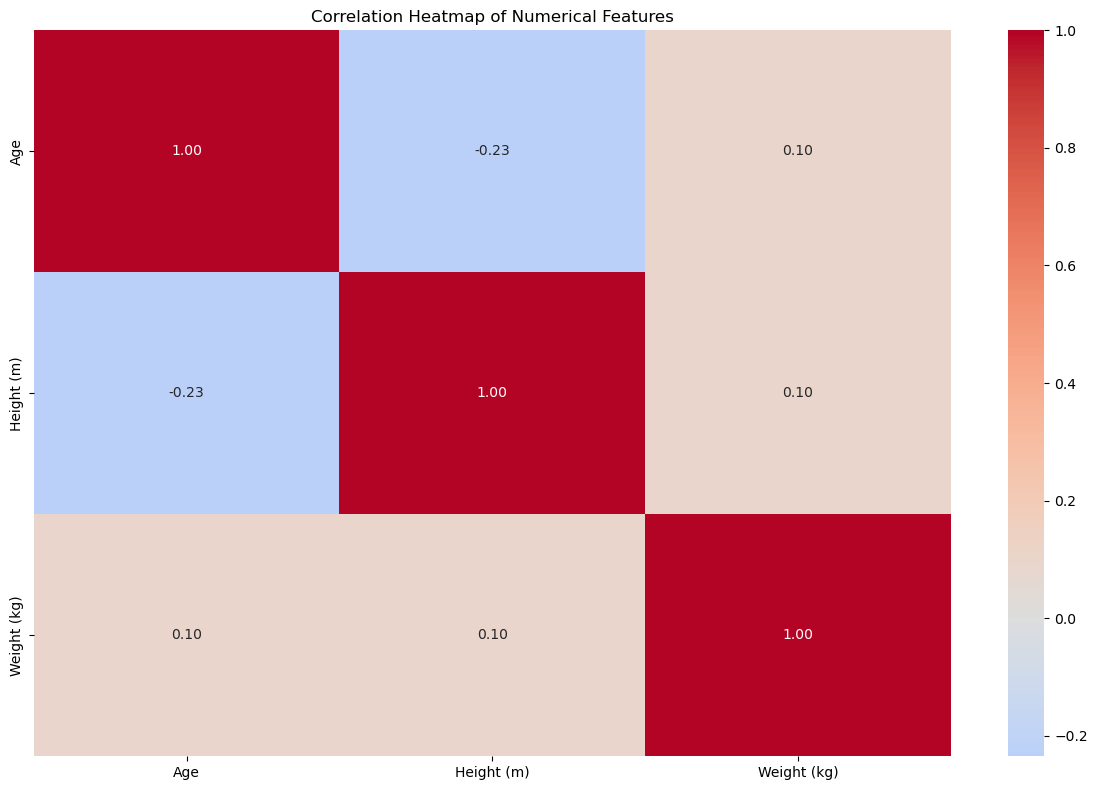

In [8]:

if len(numeric_features) >= 2:
    plt.figure(figsize=(12, 8))

    correlation_matrix = df[numeric_features].corr()

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical features to calculate correlations.")


In [9]:

from sklearn.model_selection import train_test_split

TARGET = "Obesity level"

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Remove obvious identifier columns if present
possible_id_columns = [
    col for col in X.columns
    if col.strip().lower() in {
        "id", "index", "unnamed: 0", "record_id", "person_id"
    }
]

X = X.drop(columns=possible_id_columns, errors="ignore")

# Check whether every class has enough observations for stratification
if y.value_counts().min() < 2:
    raise ValueError(
        "At least one target class has fewer than two observations. "
        "Check the target distribution before splitting."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (1745, 16)
Testing features: (437, 16)
Training target: (1745,)
Testing target: (437,)


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify feature types from the training data
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

transformers = []

# Numerical preprocessing
if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

# Categorical preprocessing
if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# Build the complete model pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42))
])

print("Logistic Regression pipeline created successfully!")


Logistic Regression pipeline created successfully!


Logistic Regression training completed!

===== LOGISTIC REGRESSION RESULTS =====
Accuracy:           0.8856
Weighted Precision: 0.8870
Weighted Recall:    0.8856
Weighted F1-score:  0.8849

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.95      0.91      0.93        76
      Normal_Weight       0.87      0.93      0.90       106
     Obesity_Type_I       0.85      0.84      0.85        63
    Obesity_Type_II       0.92      0.77      0.84        57
   Obesity_Type_III       0.87      0.96      0.91        50
         Overweight       0.87      0.87      0.87        85

           accuracy                           0.89       437
          macro avg       0.89      0.88      0.88       437
       weighted avg       0.89      0.89      0.88       437



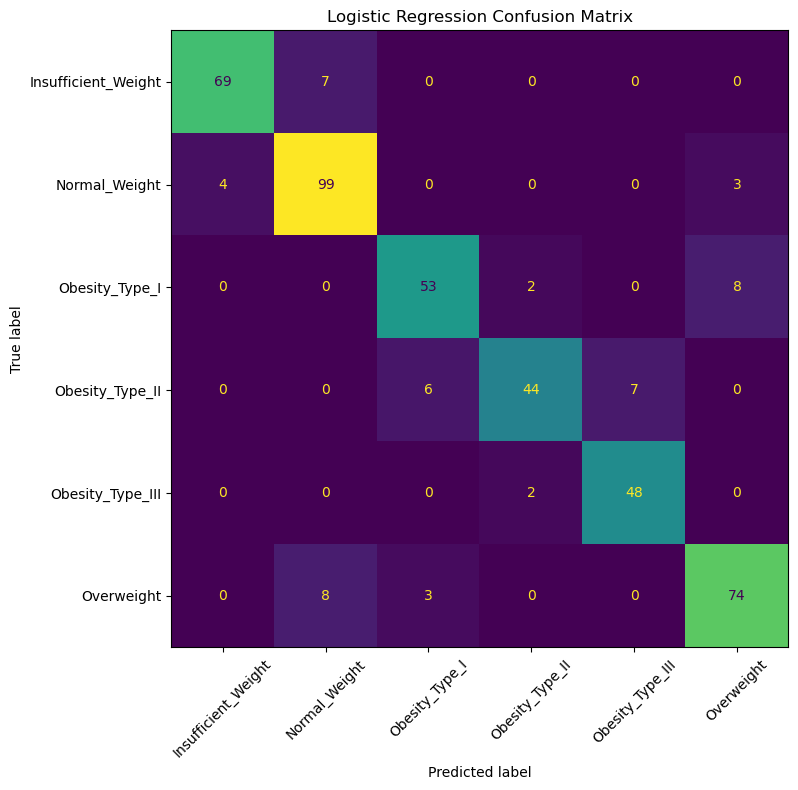

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

# Predict test-set labels
y_pred = logistic_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("\n===== LOGISTIC REGRESSION RESULTS =====")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
class_labels = logistic_model.named_steps["classifier"].classes_

cm = confusion_matrix(y_test, y_pred, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

from sklearn.model_selection import StratifiedKFold, cross_validate

# Choose a fold count supported by the smallest training class
n_splits = min(5, int(y_train.value_counts().min()))

if n_splits >= 2:
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    scoring = {
        "accuracy": "accuracy",
        "precision_weighted": "precision_weighted",
        "recall_weighted": "recall_weighted",
        "f1_weighted": "f1_weighted"
    }

    cv_results = cross_validate(
        logistic_model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"{n_splits}-Fold Stratified Cross-Validation Results")

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]
        print(
            f"{metric}: {scores.mean():.4f} "
            f"+/- {scores.std():.4f}"
        )
else:
    print("Cross-validation skipped because a class has too few records.")


5-Fold Stratified Cross-Validation Results
accuracy: 0.8934 +/- 0.0206
precision_weighted: 0.8947 +/- 0.0201
recall_weighted: 0.8934 +/- 0.0206
f1_weighted: 0.8931 +/- 0.0204


In [13]:

import os
import joblib

# Create output folder
output_dir = "outputs/person1"
os.makedirs(output_dir, exist_ok=True)

# Save test metrics
metrics_df = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision_Weighted": precision,
    "Recall_Weighted": recall,
    "F1_Weighted": f1
}])

metrics_df.to_csv(
    os.path.join(output_dir, "person1_logistic_metrics.csv"),
    index=False
)

# Save classification report
report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    os.path.join(output_dir, "person1_classification_report.csv")
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=[f"Actual_{label}" for label in class_labels],
    columns=[f"Predicted_{label}" for label in class_labels]
).to_csv(
    os.path.join(output_dir, "person1_confusion_matrix.csv")
)

# Save trained pipeline
joblib.dump(
    logistic_model,
    os.path.join(output_dir, "person1_logistic_pipeline.joblib")
)

print("All results saved in:", os.path.abspath(output_dir))
print("Saved files:", os.listdir(output_dir))


All results saved in: C:\Users\Admin\Obesity-Ml-Project\outputs\person1
Saved files: ['person1_classification_report.csv', 'person1_confusion_matrix.csv', 'person1_logistic_metrics.csv', 'person1_logistic_pipeline.joblib']
